# 02 — Exploratory Data Analysis

Loads the processed panel from `01_panel_build.ipynb` and explores it:
state-wise conversion ratio ranking, correlation against covariates, and
a first look at the "subsidy paradox" hypothesis.

**Run `01_panel_build.ipynb` first** — this notebook reads its output.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROCESSED = Path("../data/processed")

snapshots = pd.read_csv(PROCESSED / "pmsg_snapshots_long.csv")
covariates = pd.read_csv(PROCESSED / "state_covariates_wide.csv")

print("Snapshots:", snapshots.shape)
print("Covariates:", covariates.shape)

Snapshots: (284, 5)
Covariates: (36, 11)


## 1. Build the primary cross-section (Aug 2026 snapshot)

In [2]:
aug = (snapshots[snapshots["date"] == "2026-08-23"]
       .pivot_table(index="state", columns="metric", values="value", aggfunc="first")
       .reset_index())
aug = aug.rename(columns={
    "discom_applications": "applications_aug2026",
    "discom_installations": "installations_aug2026",
    "discom_households_benefited": "households_aug2026",
    "conversion_ratio": "target_conversion_ratio",
})

modeling_df = aug.merge(covariates, on="state", how="left")
modeling_df = modeling_df.sort_values("target_conversion_ratio", ascending=False)
modeling_df.to_csv(PROCESSED / "modeling_table.csv", index=False)

print(modeling_df.shape)
modeling_df.head(10)

(35, 15)


,state,target_conversion_ratio,applications_aug2026,households_aug2026,installations_aug2026,tariff_domestic4kw_2024_paise_per_kwh,tariff_domestic4kw_2025_paise_per_kwh,solar_potential_6.69pct_wasteland_gw,solar_potential_3pct_wasteland_gw,tod_domestic_applicable,irradiance_annual_kwh_m2_day,mnre_nonre_capacity_2018_mw,mnre_re_capacity_2018_mw,mnre_nonre_capacity_2025_mw,mnre_re_capacity_2025_mw
21,Mizoram,0.9291,1552.0,1444.0,1442.0,760.0,760.0,0.61,9.09,No,4.7237,0.00,100.16,0.00,135.86
16,Lakshadweep,0.8718,1427.0,1244.0,1244.0,508.0,588.0,NaN,NaN,NaN,NaN,0.00,3.14,26.83,4.97
5,Chandigarh,0.8700,1638.0,1425.0,1425.0,393.0,442.0,0.02,NaN,No,NaN,0.00,26.01,0.00,78.85
29,Tamil Nadu,0.8587,107356.0,107805.0,92186.0,569.0,596.0,204.77,17.67,No,5.2224,16638.90,13451.70,17841.38,25241.36
17,Madhya Pradesh,0.7954,77490.0,65091.0,61634.0,964.5,977.5,318.97,61.66,No,5.2231,17065.00,6445.13,22000.00,10827.70
15,Ladakh,0.7826,2824.0,2210.0,2210.0,340.0,357.0,8.56,0.00,No,NaN,0.00,0.00,0.00,142.59
25,Puducherry,0.7786,6857.0,5410.0,5339.0,473.0,540.0,0.20,NaN,No,NaN,32.50,0.34,32.50,54.51
7,Goa,0.7773,4575.0,4779.0,3556.0,341.0,373.0,6.75,0.88,No,5.3167,48.00,1.08,48.00,58.43
14,Kerala,0.7578,433725.0,335307.0,328671.0,886.0,911.0,12.40,6.11,YES — explicit domestic ToD category,5.4017,693.54,2282.06,693.54,3853.38
33,Uttarakhand,0.7260,141345.0,102903.0,102610.0,594.0,643.0,4.44,16.80,No,5.0047,450.00,4379.83,664.00,5010.77


## 2. State-wise conversion ratio ranking

This is your headline chart — the full spread of adoption efficiency across states.
Range found: **Arunachal Pradesh (~1.5%) to Mizoram (~92.9%)** — this reproduces and
extends the literature's "subsidy paradox" finding (P2/P3: 1.15%–85.91%).

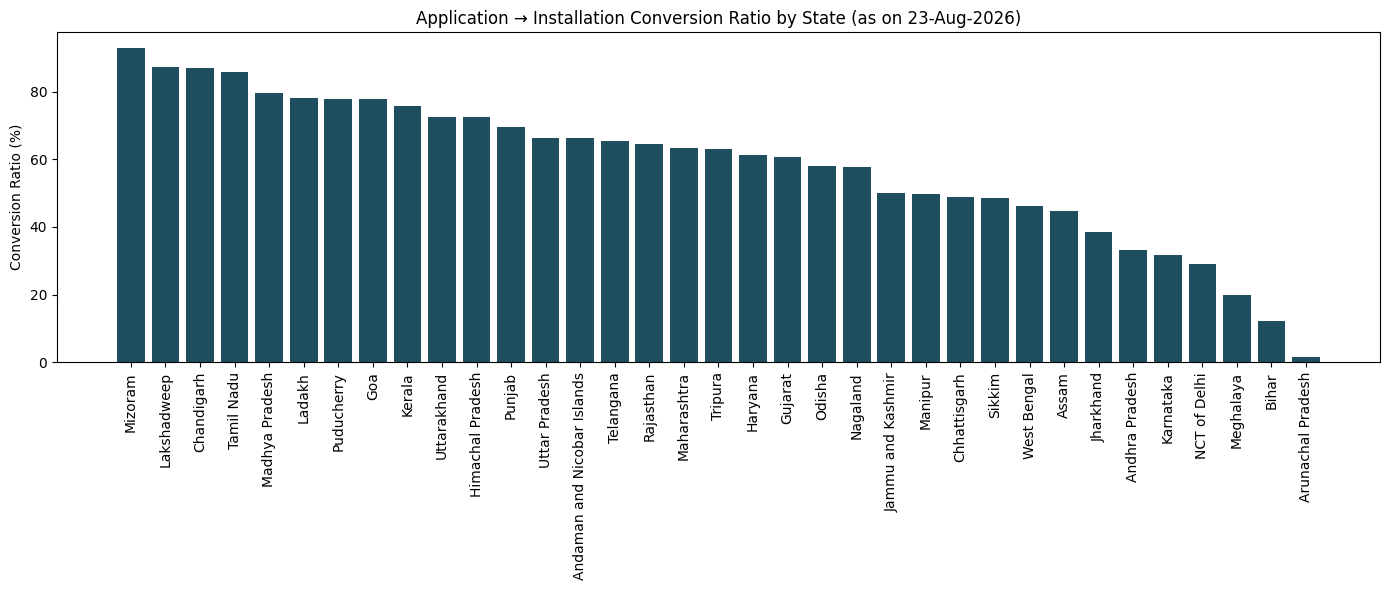

In [3]:
plot_df = modeling_df.dropna(subset=["target_conversion_ratio"])

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(plot_df["state"], plot_df["target_conversion_ratio"] * 100, color="#1F4E5F")
ax.set_ylabel("Conversion Ratio (%)")
ax.set_title("Application → Installation Conversion Ratio by State (as on 23-Aug-2026)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("../data/processed/conversion_ratio_by_state.png", dpi=150)
plt.show()

## 3. Correlation against covariates

In [4]:
modeling_df["tariff_growth_pct"] = (
    (modeling_df["tariff_domestic4kw_2025_paise_per_kwh"] - modeling_df["tariff_domestic4kw_2024_paise_per_kwh"])
    / modeling_df["tariff_domestic4kw_2024_paise_per_kwh"]
)

numeric_cols = [
    "applications_aug2026", "installations_aug2026", "households_aug2026",
    "tariff_domestic4kw_2024_paise_per_kwh", "tariff_domestic4kw_2025_paise_per_kwh",
    "tariff_growth_pct",
    "solar_potential_6.69pct_wasteland_gw", "solar_potential_3pct_wasteland_gw",
    "irradiance_annual_kwh_m2_day",
    "mnre_nonre_capacity_2018_mw", "mnre_re_capacity_2018_mw",
    "mnre_nonre_capacity_2025_mw", "mnre_re_capacity_2025_mw",
]

corrs = {}
for col in numeric_cols:
    sub = modeling_df[["target_conversion_ratio", col]].dropna()
    if len(sub) >= 8:
        corrs[col] = (sub["target_conversion_ratio"].corr(sub[col]), len(sub))

corr_df = pd.DataFrame(
    [(k, v[0], v[1]) for k, v in corrs.items()],
    columns=["feature", "correlation", "n"]
).sort_values("correlation", key=abs, ascending=False)

corr_df

,feature,correlation,n
5,tariff_growth_pct,0.526149,34
8,irradiance_annual_kwh_m2_day,0.509700,28
1,installations_aug2026,0.149089,35
2,households_aug2026,0.142255,35
7,solar_potential_3pct_wasteland_gw,0.096446,31
12,mnre_re_capacity_2025_mw,0.089210,35
6,solar_potential_6.69pct_wasteland_gw,0.065067,34
3,tariff_domestic4kw_2024_paise_per_kwh,-0.064836,34
10,mnre_re_capacity_2018_mw,0.064227,35
4,tariff_domestic4kw_2025_paise_per_kwh,0.022916,34


## 4. Key finding

`tariff_growth_pct` and `irradiance_annual_kwh_m2_day` show the strongest correlation
with conversion ratio. Raw `tariff level` and `solar potential` show almost none.

**This is the core evidence against "subsidy amount alone explains adoption"** —
tariff *momentum* and physical resource fit matter more than subsidy generosity
or theoretical potential.

**Caveat:** these are Pearson correlations on a small sample (n=28-35). Treat as
suggestive, not conclusive — see `03_modeling.ipynb` for a proper cross-validated
model comparison.

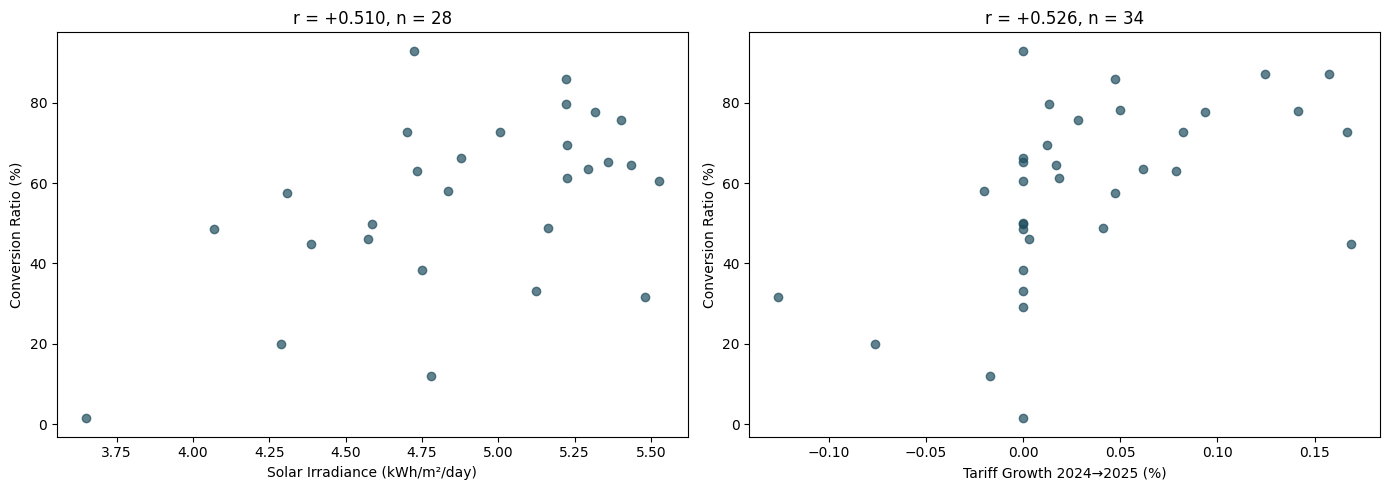

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, label in zip(
    axes,
    ["irradiance_annual_kwh_m2_day", "tariff_growth_pct"],
    ["Solar Irradiance (kWh/m²/day)", "Tariff Growth 2024→2025 (%)"]
):
    sub = modeling_df[["target_conversion_ratio", col]].dropna()
    ax.scatter(sub[col], sub["target_conversion_ratio"] * 100, color="#1F4E5F", alpha=0.7)
    ax.set_xlabel(label)
    ax.set_ylabel("Conversion Ratio (%)")
    r = sub["target_conversion_ratio"].corr(sub[col])
    ax.set_title(f"r = {r:+.3f}, n = {len(sub)}")

plt.tight_layout()
plt.savefig("../data/processed/scatter_correlations.png", dpi=150)
plt.show()

Next: open `03_modeling.ipynb` to build and evaluate a predictive model.